# Практическая работа №2
## Разведочный анализ данных (EDA)

Датасет: Titanic

Цель: изучить структуру данных, найти пропуски,
выбросы и связи между признаками.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/titanic.csv")

display(df.head())
print("Размер данных:", df.shape)

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Размер данных: (891, 12)


In [2]:
df.info()

print("\nПропущенные значения:")
print(df.isnull().sum())

print("\nСтатистика числовых признаков:")
display(df.describe())

print("\nСтатистика категориальных признаков:")
display(df.describe(include="object"))

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 83.7 KB

Пропущенные значения:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: i

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200



Статистика категориальных признаков:


/var/folders/js/0t073ybn02v1fknn231qlvgr0000gn/T/ipykernel_81990/4134932823.py:10: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  display(df.describe(include="object"))


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


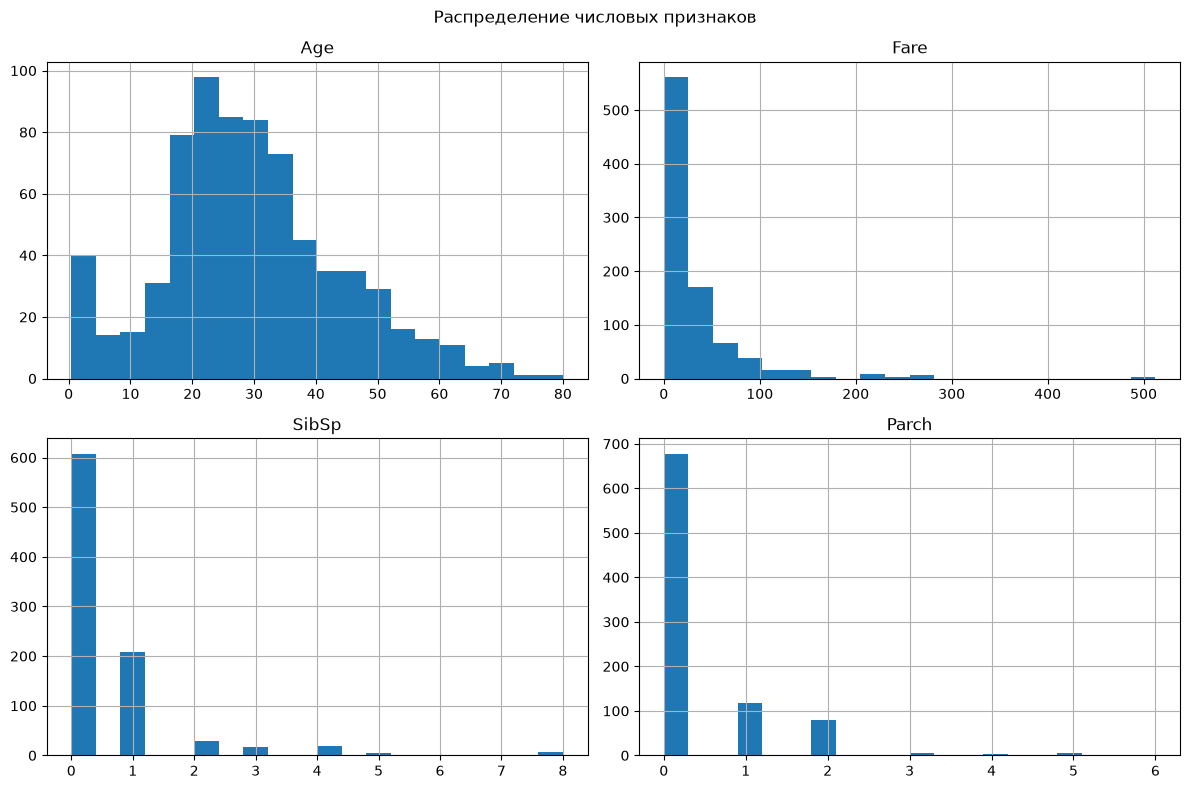

In [3]:
numeric_cols = ["Age", "Fare", "SibSp", "Parch"]

df[numeric_cols].hist(figsize=(12, 8), bins=20)

plt.suptitle("Распределение числовых признаков")
plt.tight_layout()
plt.show()

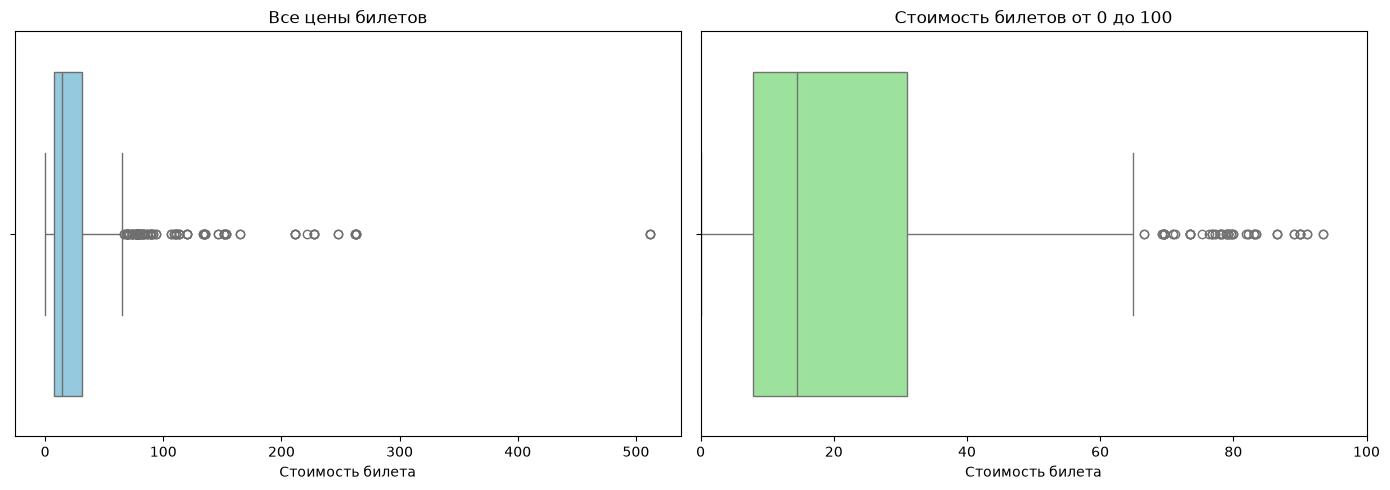

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Первый график — все значения
sns.boxplot(x=df["Fare"], ax=axes[0], color="skyblue")
axes[0].set_title("Все цены билетов")
axes[0].set_xlabel("Стоимость билета")

# Второй график — увеличенный масштаб
sns.boxplot(x=df["Fare"], ax=axes[1], color="lightgreen")
axes[1].set_xlim(0, 100)
axes[1].set_title("Стоимость билетов от 0 до 100")
axes[1].set_xlabel("Стоимость билета")

plt.tight_layout()
plt.show()

In [5]:
q1 = df["Fare"].quantile(0.25)
q3 = df["Fare"].quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

outliers = df[df["Fare"] > upper_bound]

print("Верхняя граница:", upper_bound)
print("Количество потенциальных выбросов:", len(outliers))

Верхняя граница: 65.6344
Количество потенциальных выбросов: 116


### Анализ выбросов

На первом графике заметны очень дорогие билеты, стоимость которых достигает примерно 512. Из-за них основная часть данных выглядит сжатой.

На втором графике увеличен масштаб до 100, поэтому лучше видно распределение большинства билетов и потенциальные выбросы.

Пока выбросы не удаляем, поскольку высокая стоимость билета не обязательно является ошибкой.

In [6]:
categorical_cols = ["Sex", "Pclass", "Embarked"]

for col in categorical_cols:
    print(f"\nПризнак: {col}")
    print(df[col].value_counts(dropna=False))


Признак: Sex
Sex
male      577
female    314
Name: count, dtype: int64

Признак: Pclass
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Признак: Embarked
Embarked
S      644
C      168
Q       77
NaN      2
Name: count, dtype: int64


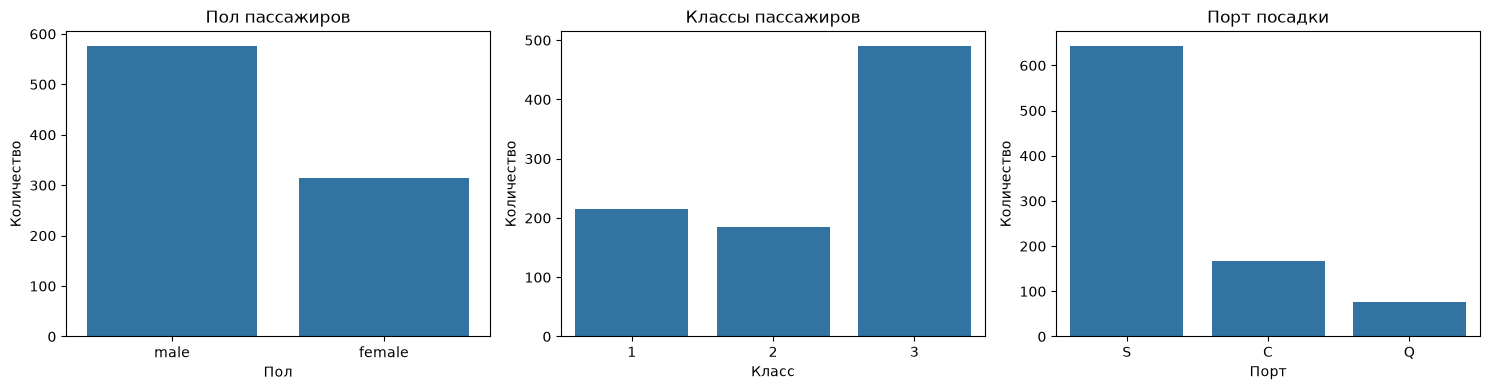

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.countplot(data=df, x="Sex", ax=axes[0])
axes[0].set_title("Пол пассажиров")
axes[0].set_xlabel("Пол")
axes[0].set_ylabel("Количество")

sns.countplot(data=df, x="Pclass", ax=axes[1])
axes[1].set_title("Классы пассажиров")
axes[1].set_xlabel("Класс")
axes[1].set_ylabel("Количество")

sns.countplot(data=df, x="Embarked", ax=axes[2])
axes[2].set_title("Порт посадки")
axes[2].set_xlabel("Порт")
axes[2].set_ylabel("Количество")

plt.tight_layout()
plt.show()

In [8]:
for col in categorical_cols:
    counts = df[col].value_counts(dropna=False)
    rare = counts[counts < 10]

    print(f"\nРедкие категории в {col}:")
    print(rare if not rare.empty else "Нет категорий с частотой менее 10")


Редкие категории в Sex:
Нет категорий с частотой менее 10

Редкие категории в Pclass:
Нет категорий с частотой менее 10

Редкие категории в Embarked:
Embarked
NaN    2
Name: count, dtype: int64


### Вывод по категориальным признакам

В датасете мужчин больше, чем женщин. Большинство пассажиров путешествовали третьим классом. Среди портов посадки чаще всего встречается Southampton (S).

В признаке Embarked имеются пропущенные значения, которые необходимо обработать перед обучением модели. Редкие категории с частотой менее 10 среди рассмотренных признаков не обнаружены.

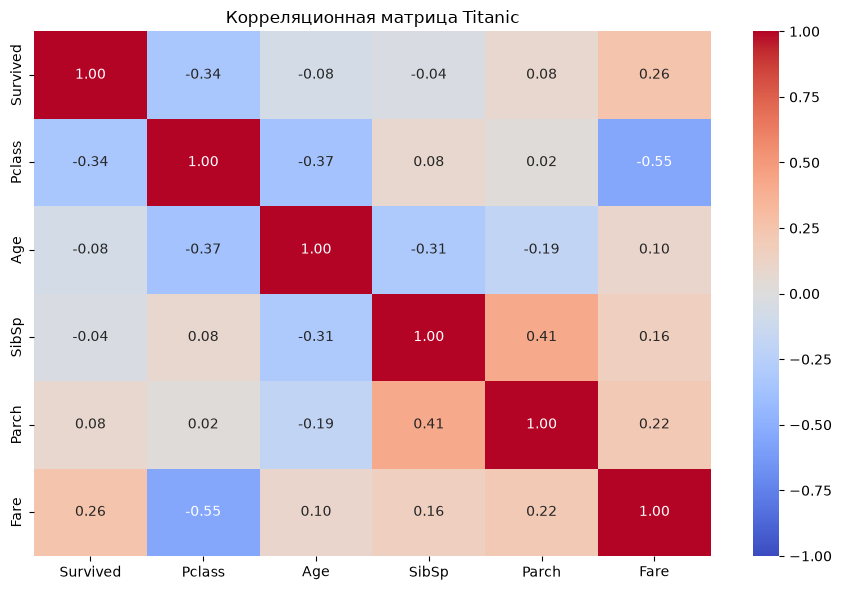

In [9]:
corr_cols = [
    "Survived", "Pclass", "Age",
    "SibSp", "Parch", "Fare"
]

corr = df[corr_cols].corr()

plt.figure(figsize=(9, 6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Корреляционная матрица Titanic")
plt.tight_layout()
plt.show()

### Вывод по корреляции

Между Pclass и Fare наблюдается отрицательная корреляция. Это означает, что пассажиры более высокого класса, обозначенного меньшим числом, обычно платили больше.

Также заметна связь между Pclass и Survived. При этом корреляция не доказывает причинно-следственную связь.

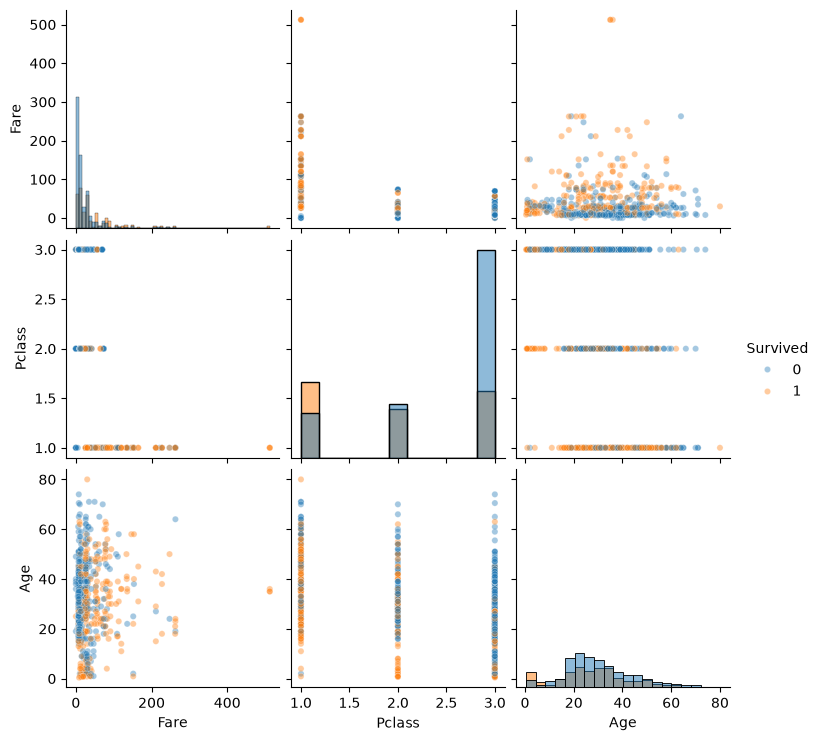

In [10]:
sns.pairplot(
    df,
    vars=["Fare", "Pclass", "Age"],
    hue="Survived",
    diag_kind="hist",
    plot_kws={"alpha": 0.4, "s": 20}
)

plt.show()

### Вывод по диаграммам рассеяния

Стоимость билета связана с классом пассажира. При этом выжившие и погибшие встречаются в разных возрастных и ценовых группах. По этим признакам нельзя точно определить, выжил пассажир или нет.

Survived
0    549
1    342
Name: count, dtype: int64
Survived
0    61.616162
1    38.383838
Name: proportion, dtype: float64


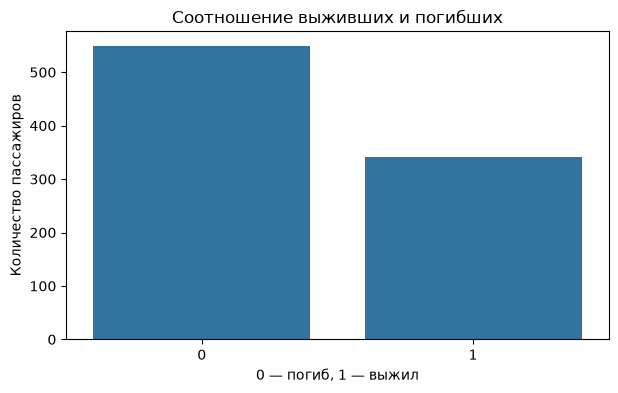

In [11]:
print(df["Survived"].value_counts())
print(df["Survived"].value_counts(normalize=True) * 100)

plt.figure(figsize=(7, 4))
sns.countplot(data=df, x="Survived")

plt.title("Соотношение выживших и погибших")
plt.xlabel("0 — погиб, 1 — выжил")
plt.ylabel("Количество пассажиров")

plt.show()

### Вывод по целевой переменной

В датасете около 61,6% пассажиров погибли, а 38,4% выжили. Наблюдается умеренный дисбаланс классов. При обучении модели необходимо учитывать это распределение.

## Итоговый отчёт EDA

1. В столбце Age есть пропущенные значения. Планируется заполнить их медианой.
2. В столбце Cabin отсутствует большая часть данных. Можно исключить этот столбец либо создать новый признак наличия информации о каюте.
3. В Embarked есть несколько пропусков. Их можно заполнить наиболее частой категорией.
4. В Fare обнаружены потенциальные выбросы. Перед удалением необходимо проверить их корректность.
5. Категориальные признаки Sex и Embarked необходимо преобразовать в числовой формат.
6. Целевая переменная Survived распределена неравномерно. При разделении данных следует использовать стратификацию.
7. Между некоторыми признаками существуют корреляции. При построении модели необходимо учитывать эти связи и избегать утечки данных.

**План следующего этапа:** разделить данные на обучающую и тестовую выборки, заполнить пропуски и выполнить кодирование категориальных признаков. Все преобразования, использующие статистики данных, должны обучаться только на тренировочной выборке.